# Pangeo-Fish による魚類の位置推定

**放流から再捕までのあいだ、魚はどこを移動していたのでしょうか？** このワークショップでは、タグが記録した水温を海洋モデルの水温や音響テレメトリーの受信記録と組み合わせ、各時刻に魚がいた可能性のある場所を推定します。

使うのは、M. Gonse ほかの研究 "Combining acoustic telemetry with archival tagging to investigate the spatial dynamic of the understudied pollack, *Pollachius pollachius*"（*Journal of Fish Biology* 106(5): 1400–1421, 2024, [doi:10.1111/jfb.15750](https://doi.org/10.1111/jfb.15750)）のタグ `A19124` です。このアーカイバルタグ（Data Storage Tag、DST）は水温と深度を記録しています。放流と再捕（または死亡）の情報も、位置を絞り込む追加の手がかりになります。

このノートブックは、すぐに使える FRA 横浜ワークショップ用の環境で動かすことを前提にしています。カーネルは **Python (pangeo-fish)** を選んでください。準備の詳細は「[事前登録](users-getting-started.md)」のページにあります。

Pangeo@EOSC の登録が承認されたら、まず [Pangeo@EOSC にログイン](https://pangeo-eosc.vm.fedcloud.eu/hub/login)してください。ログインしたらこのページに戻り、下の起動リンクを使います。ログインしていない状態では、起動リンクが正しく動かないことがあります。

**<a href="https://pangeo-eosc.vm.fedcloud.eu/hub/spawn?profile=only-choice&amp;profile-option-only-choice--image--unlisted-choice=ghcr.io%2Fpangeo-fish%2Fpangeo-fish-notebook%3A2026.11.2&amp;next=%2Fhub%2Fuser-redirect%2Fgit-pull%3Frepo%3Dhttps%253A%252F%252Fgithub.com%252Fpangeo-fish%252Fpangeo-fish-fra2026%26urlpath%3Dlab%252Ftree%252Fpangeo-fish-fra2026%252Fdocs%252Fpangeo-fish.ipynb%26branch%3Dmain">ここをクリックして、ワークショップの環境を起動し、このノートブックを開きます</a>**。

または、ログインしたあとで、次の URL をコピーしてブラウザのアドレスバーに貼り付けてください。

```
https://pangeo-eosc.vm.fedcloud.eu/hub/spawn?profile=only-choice&profile-option-only-choice--image--unlisted-choice=ghcr.io%2Fpangeo-fish%2Fpangeo-fish-notebook%3A2026.11.2&next=%2Fhub%2Fuser-redirect%2Fgit-pull%3Frepo%3Dhttps%253A%252F%252Fgithub.com%252Fpangeo-fish%252Fpangeo-fish-fra2026%26urlpath%3Dlab%252Ftree%252Fpangeo-fish-fra2026%252Fdocs%252Fpangeo-fish.ipynb%26branch%3Dmain
```

ワークショップの内容を絞るため、このノートブックでは水温と音響テレメトリーの観測だけを使います。海底地形と潮汐の情報を加えた解析は、続きのノートブック「[Pangeo-Fish による魚類の位置推定：海底地形と潮汐を加える（仮）](pangeo-fish-complete.ipynb)」で扱います。光による位置推定は、このチュートリアルでは扱いません。光による尤度（likelihood）は開発済みで、ワークショップ版への組み込みを待っている段階です。このテーマでワークショップを希望される場合は、[Pangeo-Fish のメインリポジトリで issue を作成](https://github.com/pangeo-fish/pangeo-fish/issues/new/choose)してください。

科学的な背景や理論の解説は、[日本語の科学・技術解説を読むために](science/00_guide.md)にまとめています。

> 公開ページの図は、Mac 上の Pangeo-Fish 2026.11.2 で実行した結果です。タグは A19124、海洋モデルは日次 IBI 再解析、HEALPix の格子は WGS84（レベル 10）です。 対話型の地図は、ノートブックを JupyterLab で実行すると操作できます。

**解析の流れ**

1. **解析の準備：** ツールを読み込み、解析の設定を選びます。
2. **水温の比較：** 候補となる場所ごとに、タグの観測値と海洋モデルの水温を比べます。
3. **等面積の格子を使う：** 候補となる場所を HEALPix のセルで表します。
4. **水温と合う場所を見つける：** 水温がよく一致する場所ほど大きな重みを与えます。
5. **音響テレメトリーの受信記録を加える：** 受信機での受信記録を使って場所を絞り込みます。
6. **手がかりを統合する：** 各時刻で、これらの観測をひとつにまとめます。
7. **移動を推定する：** 時刻と時刻のあいだに魚がどのくらいの範囲を移動できるかを推定します。
8. **位置と移動経路を推定する：** 観測と移動モデルを組み合わせます。
9. **結果を見る：** 地図を確認し、移動経路を比べ、動画を作ります。
10. **次のステップ（GFTS）：** Destination Earth で、自分の魚を将来の海水温と並べて見てみます。

観測を時間方向につなぐために、隠れマルコフモデル（Hidden Markov Model、HMM）を使います。魚の位置は直接わかりません。このモデルは、観測と移動についての仮定の両方を使って、魚がいた可能性のある場所を推定します。

くわしい説明は[HMM による位置分布と移動経路の推定](science/02_hmm.md)を見てください。

## 1. 解析の準備

セルは上から順に実行してください。コードセルをクリックして **Shift+Enter** を押すと、そのセルが実行され、次のセルに移ります。計算が終わるのを待ってから次に進んでください。セルでエラーが出たら、そのあとのステップを実行する前に講師に声をかけてください。あとで問題を報告するときは、このノートブックの最後にある付録「**バグ報告用の情報（Information for bug reports）**」のセルを実行し、その出力を報告に貼り付けてください。

ワークショップの環境には、必要な Python パッケージがすでに入っています。下の準備用のセルは、変更せずにそのまま実行してください。

このセルは、ワークショップで使う計算環境を選びます。そのまま実行してください。

In [1]:
# CPU で実行します。
import torch
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""

### 解析ツールを読み込む

In [2]:
# pangeo-fish が読み込む movingpandas は、使わない追加機能（Stone Soup）について
# 警告を出します。解析には関係がないので、この警告だけを表示しないようにします。
import warnings

warnings.filterwarnings(
    "ignore", message="Missing optional dependencies", category=UserWarning
)

In [3]:
from pint_xarray import unit_registry as ureg
import hvplot.xarray
import xarray as xr
import sys

# sys.path.append("../")
import pangeo_fish
from pangeo_fish.xarray_update import Accessor
from pangeo_fish.helpers import multiplot_healpix, multi_map_with_synced_sliders

### 解析の設定

設定はすべてここにまとめ、使うセクションごとに分けてあります。最初は、用意された値のまま実行してください。ご自身の研究で使うときは、タグ、解析する海域、水温の許容幅、受信機の受信範囲の 4 つが特に重要な選択になります。

In [4]:
# セクション 1 — 初期化と設定
# タグの公開 ID。
tag_name = "A19124"


# タグデータの場所：公開 URL、ローカルのパス、または s3:// のバケットのパス。
tag_root = "https://data-taos.ifremer.fr/demo/tag/tag/"

tag_storage_options = None
# 予備：同じタグデータを Pangeo@EOSC の MinIO にミラーしたもの（公開、読み取り専用）。
# data-taos.ifremer.fr につながらないときは、上の 2 行の代わりにこちらを使います。
# tag_root = "s3://todaka-pangeo-fish-demo/tag"
# tag_storage_options = {
#     "anon": True,
#     "client_kwargs": {"endpoint_url": "https://pangeo-eosc-minioapi.vm.fedcloud.eu"},
# }

# WGS84 の格子での結果を保存するフォルダー。この設定を変える場合、以前に球面の
# 格子で計算した結果が残っているフォルダーは使わず、新しいフォルダーにしてください。
scratch_root = "./test/wgs84/level10"

# scratch_root の下で結果を読み書きするための接続設定。
# None ではデフォルトの設定を使います。
# scratch_root が s3:// の場合は、認証情報・プロファイルやエンドポイントの設定を指定します。
storage_options = None

# まとめて処理する時刻の数。デフォルトの値です。
# 1 = チャンクごとに 1 時刻、-1 = すべての時刻を 1 つのチャンクに。
chunk_time = 1

# セクション 2 — 参照モデルの海洋データとアーカイバルタグ（DST）の観測を比べる
# Copernicus Marine の海洋モデルを選びます。有効にする代入は 1 つだけにしてください。
# 切り替えるには、いま有効な行の先頭に # を付け、使いたい行の先頭の # を外します。最初は IBI を使ってください。
# すべてのモデルと、その対象範囲・注意点：
# https://pangeo-fish.readthedocs.io/en/latest/copernicus-models.html

# IBI 再解析 — 領域モデル、約 3 km、日ごと、1993 年〜（デフォルト）
# https://data.marine.copernicus.eu/product/IBI_MULTIYEAR_PHY_005_002
copernicus_model_name = "cmems_mod_ibi_phy-temp_my_0.027deg_P1D-m"

# GLORYS12 再解析 — 全球モデル、約 9 km、日ごと、1993 年〜
# https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_PHY_001_030
# copernicus_model_name = "cmems_mod_glo_phy_my_0.083deg_P1D-m"

# 全球の解析・予報 — 約 9 km、日ごと、2022 年 6 月〜
# copernicus_model_name = "cmems_mod_glo_phy-thetao_anfc_0.083deg_P1D-m"
# 全球の解析・予報 — 約 9 km、6 時間ごと、2022 年 6 月〜（海面高度に潮汐を含まない）
# https://data.marine.copernicus.eu/product/GLOBAL_ANALYSISFORECAST_PHY_001_024
# copernicus_model_name = "cmems_mod_glo_phy-thetao_anfc_0.083deg_PT6H-i"

# 1 時間ごとの領域モデル — 直近の約 2 年分だけ（期間は順次ずれていきます）。
# A19124 の記録は 2022 年 6 月のものです。1 時間ごとのモデルを使うには、
# 観測の日付と解析する海域がそのモデルに含まれているタグを選んでください。
# IBI の解析・予報 — 約 3 km、1 時間ごと
# https://data.marine.copernicus.eu/product/IBI_ANALYSISFORECAST_PHY_005_001
# copernicus_model_name = "cmems_mod_ibi_phy_anfc_0.027deg-3D_PT1H-m"
# 北西ヨーロッパ陸棚（North-West Shelf）の解析・予報 — 1.5 km、1 時間ごと
# https://data.marine.copernicus.eu/product/NWSHELF_ANALYSISFORECAST_PHY_004_013
# copernicus_model_name = "cmems_mod_nws_phy-tem_anfc_1.5km-3D_PT1H-i"

# 選んだモデルを Copernicus Marine から読み込みます。
ref_url = None  # デフォルトの値

# モデルを読み込む範囲（緯度・経度）。セクション 3 と 9 でも使います。
bbox = {"latitude": [46, 51.5], "longitude": [-7, 0]}

# 魚が記録された深度に対して、モデルの海底が浅すぎるセルを除外します。
# 同じモデルの時間区間でのタグの最大深度にこの割合を掛けた値よりも
# 海底が浅いセルは除外されます。
# 範囲：0 以上。実用的な値は 0 から 1 のあいだです。
#   0    = フィルターなし：すべてのセルを残す（デフォルトの値）
#   0.8  = 海底がタグの最大深度の 80% 以上の深さであること
#          （モデルの海底地形の誤差をある程度許容する）
#   1    = 海底がタグの最大深度と同じかそれより深いこと
# 値が大きいほど多くのセルを除外します（より厳しい）。1 より大きいと、
# 海底が魚よりわずかに深いだけのセルも除外されます。
relative_depth_threshold = 0

# セクション 3 — HEALPix への再格子化
# 解析には HEALPix のセルを使います。セクション 3〜8 ではこの設定のままにします。
dims = ["cells"]

# HEALPix の解像度（おおよその相当ピクセルサイズ）
# refinement level が 1 つ上がるごとに、セルの面積は 1/4 になります。
# セルの総数 = 12 * 4**refinement_level
# 相当サイズ = sqrt(セルの面積)。セルは WGS84 楕円体の表面を等しい面積に
# 分けます。幾何学的な辺の長さそのものではありません。
#
# refinement_level = 9  # 約 12.7 km
refinement_level = 10  # 約 6.4 km
# refinement_level = 12  # 約 1.6 km
#
# refinement level を上げると空間解像度は細かくなりますが、
# セルの数と計算コストが増えます。

# セクション 3 の HEALPix への再格子化で使う地球の形。格子と一緒に保存され、
# 地図の描画と移動の探索はそこから読み込みます。
ellipsoid = "WGS84"

# HEALPix 格子での陸と海の区別（セクション 3）。モデルの海洋マスク
# （1 = 海、0 = 陸）を HEALPix の各セルに内挿します。海岸の近くでは
# 0 から 1 のあいだの値になり、おおよそセルのまわりの海の割合を表します。
# この値が mask_threshold 以上のセルを海として残します。それ以外の
# セルは陸として扱います。データは入らず、魚はそこにいられません。
# 範囲：0 から 1。
#   0    = 少しでも海に接しているセルをすべて残す（海岸をもっとも広くとる）
#   0.25 = およそ 4 分の 1 以上が海のセルを残す（ここで使う値：
#          湾や河口を残し、モデルの海岸線よりわずかに陸側まで含む）
#   0.5  = およそ半分以上が海のセルを残す
#          （regrid_dataset_hpresample のデフォルト。モデルの海岸線に沿う）
#   1    = 海の点に囲まれたセルだけを残す
# 値が小さいほど海岸のセルを多く残し、値が大きいほど陸が残りにくくなります。
mask_threshold = 0.25

# セクション 4 — 水温にもとづく観測確率（emission probability）
# 水温の許容幅（°C）：値が大きいほど、タグとモデルの水温の差を
# より広く許容します（ガウス分布の標準偏差）。
differences_std = 0.75
# 既知の放流地点と再捕（または死亡）地点のまわりの広がり：ガウス分布の
# 標準偏差を、地球上の角度（ラジアン）で表したもの。地球の半径を掛けると
# 距離になります：1e-4 rad x 6378 km ≈ 0.64 km。
# これは HEALPix のセル 1 つ（レベル 10 で約 6.4 km）より小さいので、位置は
# 実質的に放流（または再捕）地点のセルに固定されます。
# 値が小さいほど空間的な制約が強くなります。デフォルトの値のままにしてください。
initial_std = 1e-4
recapture_std = 1e-4

# セクション 5 — 音響テレメトリーの受信による確率
# 各受信機のまわりで想定する最大受信距離。
receiver_buffer_m = 2000

# セクション 7 — 移動のパラメータの最適化
# 移動距離を角度に変換するための地球の半径は、HEALPix 格子に保存された
# 楕円体から求めます（楕円体の長半径を使います。
# 値は "WGS84" の場合で約 6378 km）。
# 移動のパラメータの探索上限を決めるための速度の目安。
# ありうる移動のひとつひとつに対する厳密な速度制限ではありません。
maximum_speed_km_per_day = 60
# 推定のときに試す sigma の値の上限に掛ける倍率。
# 1 では maximum_speed とモデルの時間間隔で決まる上限をそのまま使い、
# 2 ではその上限を 2 倍にします。推定される移動そのものを直接何倍かにするわけではありません。
# デフォルトでは 1 のままにします。動画のコマの間引きとは関係ありません。
adjustment_factor = 1
# FFTConv で使う、カーネルの半径（sigma の何倍か）。
truncate = 5  # デフォルトの値
# パラメータ探索の数値精度。デフォルトの値です。
tolerance = 1e-6

# セクション 8 — 状態確率と移動経路
# 移動経路の要約：ビタビ経路、もっとも確率の高いセル、平均の位置を
# 各時刻について求めます。
# セクション 9 の描画でも使います。
track_modes = ["viterbi_healpix", "mode", "mean"]
# ここで指定できるのは "speed"（km/h）と、1 つ前の点からの "distance"（km）です。
# ほかの量はあとから計算できます。セクション 8 の補足を参照してください。
additional_track_quantities = ["speed", "distance"]
# sigma を手で指定する比較では、平均と最頻値の移動経路を使います。ビタビは
# 近傍が広いと計算に非常に時間がかかることがあります。上の推定したモデルとは別の設定です。
comparison_track_modes = ["mode", "mean"]

# セクション 9 — 可視化と動画の作成
# 動画のフレームとフレームのあいだのデータの時刻数
# 1 = すべての時刻を含める
# 3 = 3 時刻ごとに含める
# 現在の動画作成ツールでは最後の時刻が含まれません。セクション 9 を参照してください。
time_step = 1

In [5]:
# Papermill がパラメータを上書きしたあとで、それに依存する値を計算します。
receiver_buffer = ureg.Quantity(receiver_buffer_m, "m")
maximum_speed = ureg.Quantity(maximum_speed_km_per_day, "km / day")

In [6]:
# 解析結果を保存するルートディレクトリを決めます。
target_root = f"{scratch_root}/{tag_name}"

# 最適化で使うデフォルトのチャンクサイズを決めます。
default_chunk = {"time": chunk_time, "lat": -1, "lon": -1}
default_chunk_dims = {"time": chunk_time}
default_chunk_dims.update({d: -1 for d in dims})

### 計算の準備

このセルを実行すると Dask が起動し、使える計算資源に計算を分担させます。ここで変更する設定はありません。

In [7]:
# 分散計算のためのローカルクラスターを準備します。
from distributed import LocalCluster

cluster = LocalCluster()
client = cluster.get_client()
client

### タグの観測データを読み込む

選んだ魚の水温・深度・イベント（放流や再捕など）の情報を読み込みます。

In [8]:
from pangeo_fish.helpers import load_tag

tag, tag_log, time_slice = load_tag(
    tag_root=tag_root, tag_name=tag_name, storage_options=tag_storage_options
)
tag

<xarray.DataTree>
Group: /
│   Attributes:
│       pit_tag_id:       A19124
│       acoustic_tag_id:  OPI-372
│       scientific_name:  Pollachius pollachius
│       common_name:      Pollock
│       project:          FISHINTEL
│       tag_name:         A19124
├── Group: /dst
│       Dimensions:      (time: 20680)
│       Coordinates:
│         * time         (time) datetime64[us] 165kB 2022-06-12T22:00:00 ... 2022-07-...
│       Data variables:
│           temperature  (time) float64 165kB 17.58 17.53 17.5 ... 20.53 20.55 20.66
│           pressure     (time) float64 165kB 1.43 1.43 1.43 1.5 ... 1.81 1.81 1.81 1.81
├── Group: /tagging_events
│       Dimensions:     (event_name: 2)
│       Coordinates:
│         * event_name  (event_name) object 16B 'release' 'fish_death'
│       Data variables:
│           time        (event_name) datetime64[us] 16B 2022-06-13T11:40:30 2022-06-2...
│           longitude   (event_name) float64 16B -5.098 -5.136
│           latitude    (event_name) float64 16B 48.45 48.43
├── Group: /stations
│       Dimensions:            (deployment_id: 41)
│       Coordinates:
│         * deployment_id      (deployment_id) int64 328B 28689 28690 ... 29666 59010
│       Data variables:
│           station_name       (deployment_id) object 328B 'ancrage_mahuda' ... 'stiff'
│           deploy_time        (deployment_id) datetime64[us] 328B 2022-06-13T06:14:0...
│           deploy_longitude   (deployment_id) float64 328B -5.103 -5.112 ... -5.025
│           deploy_latitude    (deployment_id) float64 328B 48.45 48.45 ... 48.47 48.47
│           recover_time       (deployment_id) datetime64[us] 328B 2022-06-20T14:07:0...
│           recover_longitude  (deployment_id) float64 328B nan nan nan ... nan nan nan
│           recover_latitude   (deployment_id) float64 328B nan nan nan ... nan nan nan
└── Group: /acoustic
        Dimensions:        (time: 48)
        Coordinates:
          * time           (time) datetime64[us] 384B 2022-06-13T13:41:49 ... 2022-06...
        Data variables:
            deployment_id  (time) int64 384B 28689 28689 28690 ... 28690 28690 28690
            longitude      (time) float64 384B -5.103 -5.103 -5.112 ... -5.112 -5.112
            latitude       (time) float64 384B 48.45 48.45 48.45 ... 48.45 48.45 48.45

位置を推定する前に、記録された水温と深度の時系列をプロットして、観測データを確認します。

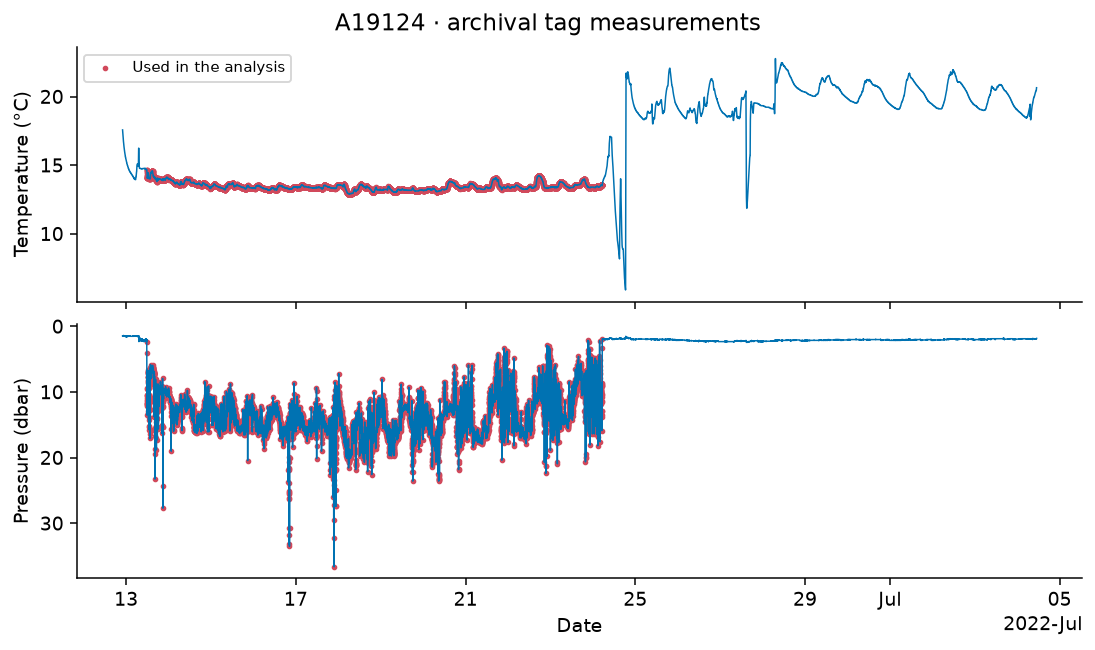

In [9]:
from pangeo_fish.helpers import plot_tag

plot = plot_tag(
    tag=tag,
    tag_log=tag_log,
    # 必要ならプロットをそのまま保存できます
    save_html=True,
    storage_options=storage_options,
    target_root=target_root,
)
plot

赤い点は、タグが生きた魚に付いていたとみなす期間の観測で、解析に使われます。この期間が放流と再捕（または死亡）の情報と合っているかを確認し、記録に欠けている部分がないかも見てください。

### Copernicus Marine にサインインする

次のセルを実行してください。求められたら、Copernicus Marine のユーザー名とパスワードを入力します。ログイン情報は保存され、次回以降のセッションでも使われます。すでに保存されている場合は、もう一度聞かれることはありません。

サインインできないときは、講師に声をかけるか、[Copernicus Marine の認証情報ガイド](https://help.marine.copernicus.eu/en/articles/8185007-copernicus-marine-toolbox-credentials-configuration)を参照してください。

In [10]:
from pathlib import Path

import copernicusmarine

credentials_file = Path.home() / ".copernicusmarine" / ".copernicusmarine-credentials"

if credentials_file.is_file():
    print("Using saved Copernicus Marine credentials.")
else:
    copernicusmarine.login()  # 必要なときにユーザー名とパスワードを尋ねます。

## 2. タグと海洋モデルの水温を比べる

### 解析する海域の海水温を読み込む

ここでは [IBI 再解析](https://data.marine.copernicus.eu/product/IBI_MULTIYEAR_PHY_005_002/services)を使います。この海域をカバーする領域海洋モデルで、日ごとのデータ、解像度は約 3 km です。次のセルで、選んだ海域とタグの装着期間のデータを読み込みます。

[GLORYS12](https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_PHY_001_030/services) は全球モデルの選択肢で、日ごとのデータ、解像度は約 9 km です。モデルを切り替えるには、上の設定セルで、いま有効な `copernicus_model_name` の行の先頭に `#` を付け、もう一方の行の先頭の `#` を外します。最初は IBI で実行してください。

In [11]:
from pangeo_fish.helpers import load_model, compute_diff

reference_model = load_model(
    uri=ref_url,
    tag_log=tag_log,
    time_slice=time_slice,
    bbox=(bbox | {"max_depth": tag_log["pressure"].max()}),
    chunk_time=chunk_time,
    remote_options={},
    copernicus_model_name=copernicus_model_name,
)

### 候補となる場所で水温を比べる

候補となる場所ごとに、タグの水温と、観測された深度でのモデルの水温を比べます。観測はモデルの時間間隔ごとにまとめられます。差が 0 に近いほど水温がよく一致していることを示しますが、似た水温の場所が複数あることもあります。

くわしい説明は[水温・深度履歴から位置の適合度を作る](science/03_temperature.md)を見てください。

In [12]:
%%time
diff = compute_diff(
    reference_model=reference_model,
    tag_log=tag_log,
    relative_depth_threshold=relative_depth_threshold,
    chunk_time=chunk_time,
    # 干出するセル（仮）（dry cells：干潮時に水柱 H0 + XE <= 0 となるセル。1 時間ごとの
    # North-West Shelf モデルだけで生じます）は、デフォルトで除外されます。ほかの選択肢：
    # min_water_depth="auto",  # デフォルト：干出するセルがあれば除外する
    # min_water_depth=0.5,  # 水深が 0.5 m 未満のセルも除外する
    # min_water_depth=None,  # 干出するセルを残す（以前の動作）
)[0]
diff = diff.compute()
diff

CPU times: user 3.99 s, sys: 1.28 s, total: 5.27 s
Wall time: 2min 6s


<xarray.Dataset> Size: 7MB
Dimensions:     (lat: 198, lon: 252, time: 11)
Coordinates:
  * lat         (lat) float32 792B 46.03 46.05 46.08 46.11 ... 51.44 51.47 51.5
  * lon         (lon) float32 1kB -6.999 -6.971 -6.944 ... -0.05448 -0.0267
    latitude    (lat, lon) float32 200kB 46.03 46.03 46.03 ... 51.5 51.5 51.5
    longitude   (lat, lon) float32 200kB -6.999 -6.971 ... -0.05448 -0.0267
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
Data variables:
    diff        (time, lat, lon) float64 4MB -2.998 -3.028 -3.052 ... nan nan
    H0          (lat, lon) float32 200kB 4.801e+03 4.792e+03 ... nan nan
    XE          (time, lat, lon) float32 2MB -0.2991 -0.2984 -0.2978 ... nan nan
    ocean_mask  (lat, lon) bool 50kB True True True True ... False False False
Attributes:
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    comment:                   pangeo-fish == 2026.11.2, healpix-convolution ...
    relative_depth_threshold:  0
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...

### データがそろっているかを時間ごとに確認する

このプロットは、各時刻でデータのある空間セルの数を数えたものです。欠損値（Python では `NaN` と表されます）は数えません。HMM を実行する前に、この確認が大切です。

急に減っているところや、途切れているところがないかを見てください。数が多少変動するのは問題ありませんが、急に減っている場合はデータの欠損や処理の問題かもしれません。**数が 0 になっている時刻は、その時刻に使える空間データがまったくないことを意味します。先に進む前に、講師と一緒に原因を調べてください。**

水温の差が 0 というのは完全に一致しているということなので、`.count()` ではデータのあるセルとして数えられます。

CPU times: user 21 ms, sys: 2.68 ms, total: 23.6 ms
Wall time: 24.2 ms


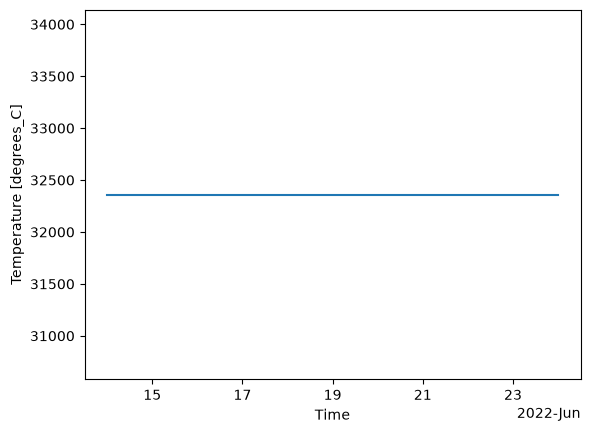

In [13]:
%%time
diff["diff"].count(["lat", "lon"]).rename("Valid grid cells").plot()

In [14]:
%%time
diff.to_zarr(
    f"{target_root}/diff.zarr", mode="w", storage_options=storage_options, zarr_format=2
)

CPU times: user 33.3 ms, sys: 55 ms, total: 88.3 ms
Wall time: 66.4 ms


## 3. 候補となる場所を等面積の格子で表す

水温の比較結果を、**HEALPix** と呼ばれる格子に移します。HEALPix は等面積の離散全球格子システム（DGGS）で、どのセルも地球表面上で同じ面積を持ちます。階層構造になっているため、細かい格子と粗い格子を選べます。このワークショップでは refinement level 10 を使い、セルの大きさは約 **6.4 km** です。

このセルの大きさは、推定した魚の位置の精度ではありません。位置の不確かさは、観測、海洋モデル、移動の仮定にも左右されます。また、等面積だからといって、セルの形がすべて同じになるわけでも、空間のゆがみがすべてなくなるわけでもありません。詳しくは [HEALPix のドキュメント](https://healpix.sourceforge.io/)を参照してください。

格子の設定についてのくわしい説明は[楕円体 HEALPix：位置・面積・解像度を区別する](science/09_ellipsoidal_healpix.md)を見てください。

In [15]:
from pangeo_fish.helpers import (
    open_diff_dataset,
    regrid_dataset_hpresample,
)

In [16]:
# 前のステップのデータセットを開きます（ノートブックをここから再開するときだけ必要です）
diff = open_diff_dataset(target_root=target_root, storage_options=storage_options)
diff

<xarray.Dataset> Size: 7MB
Dimensions:     (time: 11, yi: 198, xi: 252)
Coordinates:
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    latitude    (yi, xi) float32 200kB 46.03 46.03 46.03 ... 51.5 51.5 51.5
    longitude   (yi, xi) float32 200kB -6.999 -6.971 -6.944 ... -0.05448 -0.0267
Dimensions without coordinates: yi, xi
Data variables:
    diff        (time, yi, xi) float64 4MB dask.array<chunksize=(6, 99, 126), meta=np.ndarray>
    H0          (yi, xi) float32 200kB dask.array<chunksize=(198, 252), meta=np.ndarray>
    ocean_mask  (yi, xi) bool 50kB dask.array<chunksize=(198, 252), meta=np.ndarray>
    XE          (time, yi, xi) float32 2MB dask.array<chunksize=(6, 99, 126), meta=np.ndarray>
Attributes:
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    comment:                   pangeo-fish == 2026.11.2, healpix-convolution ...
    relative_depth_threshold:  0
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...

In [17]:
reshaped, resampling_info = regrid_dataset_hpresample(
    ds=diff,
    refinement_level=refinement_level,
    ellipsoid=ellipsoid,
    dims=dims,
    mask_threshold=mask_threshold,
)
reshaped

[KNeighborsResampler] dropping 1,302 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).


[CloughTocherResampler] N=32359 samples, 64307 Delaunay triangles, K=6257 output cells retained (inside convex hull).
ocean cells not covered by Clough-Tocher : 297
iocean cells  not covered by CT nor by rewrap : 75
diff ('time', 'yi', 'xi')


H0 ('yi', 'xi')
XE ('time', 'yi', 'xi')


<xarray.Dataset> Size: 2MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
    latitude    (cells) float64 65kB 46.01 46.06 46.11 ... 51.53 51.53 51.53
    longitude   (cells) float64 65kB 0.04777 0.04782 0.04787 ... 353.3 353.1
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    ocean_mask  (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0 1.0
    diff        (time, cells) float64 717kB nan nan nan ... -2.4 -2.094 -2.558
    H0          (cells) float64 65kB nan nan nan nan ... 82.42 82.12 82.86 80.65
    XE          (time, cells) float64 717kB nan nan nan ... -0.3025 -0.308
Attributes:
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    comment:                   pangeo-fish == 2026.11.2, healpix-convolution ...
    relative_depth_threshold:  0
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    grid_type:                 healpix
    level:                     10
    nside:                     1024

In [18]:
resampling_info["bbox"] = bbox
import json

# 再格子化のメタデータと地理的な範囲を、結果と一緒に保存します。
with open(f"{target_root}/resampling_info.json", "w") as f:
    json.dump(resampling_info, f)

with open(f"{target_root}/resampling_info.json") as f:
    resampling_info = json.load(f)
resampling_info

{'resolution_2D': [252, 198],
 'refinement_level': 10,
 'ellipsoid': 'WGS84',
 'bbox': {'latitude': [46, 51.5], 'longitude': [-7, 0]}}

格子を変えたので、データがそろっているかをもう一度確認します。セルの大きさや範囲が変わったため、セルの数は前と異なることがあります。急に減っているところがないかを見て、数が 0 の時刻があれば、先に進む前に原因を調べてください。

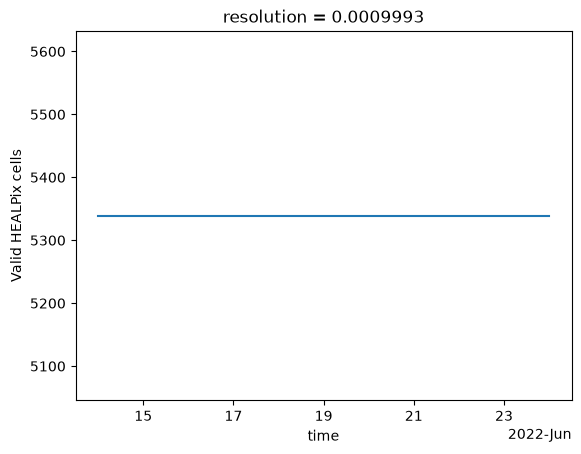

In [19]:
reshaped["diff"].count(dims).rename("Valid HEALPix cells").plot()

In [20]:
# 結果を保存します
reshaped.chunk(default_chunk_dims).to_zarr(
    f"{target_root}/diff-regridded.zarr",
    mode="w",
    consolidated=True,
    compute=True,
    storage_options=storage_options,
    zarr_format=2,
)

次の地図は、水温の差（`diff`）とモデルの海底の深さ（`H0`）を示しています。水温の差の地図では、0 に近い値を探してください。よく一致する場所は 1 か所に集まっていますか、それとも何か所かに分かれていますか？ このパターンが時間とともにどう変わるかも確認してください。

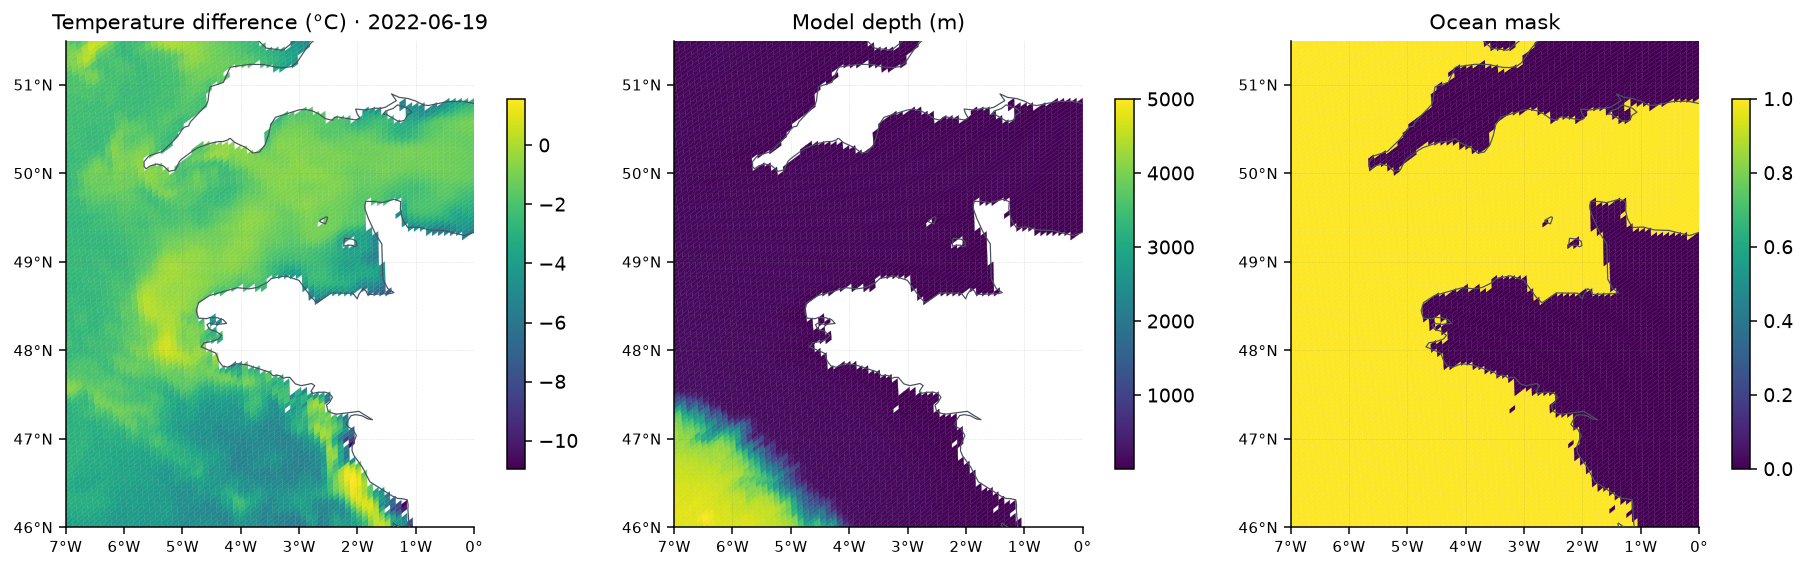

In [21]:
reshaped.healpix.plot(var=["diff", "H0", "ocean_mask"], alpha=0.5)

## 4. 水温と合う場所を見つける

モデルの水温がタグの観測と一致する場所ほど、大きな重みを与えます。この重みを**観測確率（emission probability）** と呼びます（統計学では尤度（likelihood）にあたります）。観測が、それぞれの候補の場所とどのくらい整合するかを表します。

水温の差 0 を中心とするガウス分布（正規分布）の曲線を使います。設定 `differences_std` はその幅を決めます。値を大きくすると、より大きな水温の差まで許容します。放流と再捕（または死亡）の場所も、位置を絞り込む追加の手がかりになります。

`emission_pdf["pdf"]` に保存される水温の重みは、この段階ではまだ場所全体で合計しても 1 になりません。セクション 6 で手がかりを統合し、正規化します。

In [22]:
from pangeo_fish.helpers import compute_emission_pdf

In [23]:
# 前のステップのデータセットを開きます（ノートブックをここから再開するときだけ必要です）
differences = xr.open_dataset(
    f"{target_root}/diff-regridded.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)

# ……そして観測確率の行列を計算します
emission_pdf = compute_emission_pdf(
    diff_ds=differences,
    events_ds=tag["tagging_events"].ds,
    differences_std=differences_std,
    initial_std=initial_std,
    recapture_std=recapture_std,
    dims=dims,
    chunk_time=chunk_time,
)[0]
emission_pdf

<xarray.Dataset> Size: 1MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
  * cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
    latitude    (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude   (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B ...
Dimensions without coordinates: cells
Data variables:
    pdf         (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
    initial     (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    final       (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=10, indexing_scheme=nested, kind=pandas)
Attributes: (12/15)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    grid_type:                 healpix
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001

水温の重み（`pdf`）を、放流（`initial`）と最終位置（`final`、ある場合）の地図と比べてください。水温の観測から、狭い範囲に絞り込めていますか？ それとも、可能性のある海域がいくつも残っていますか？

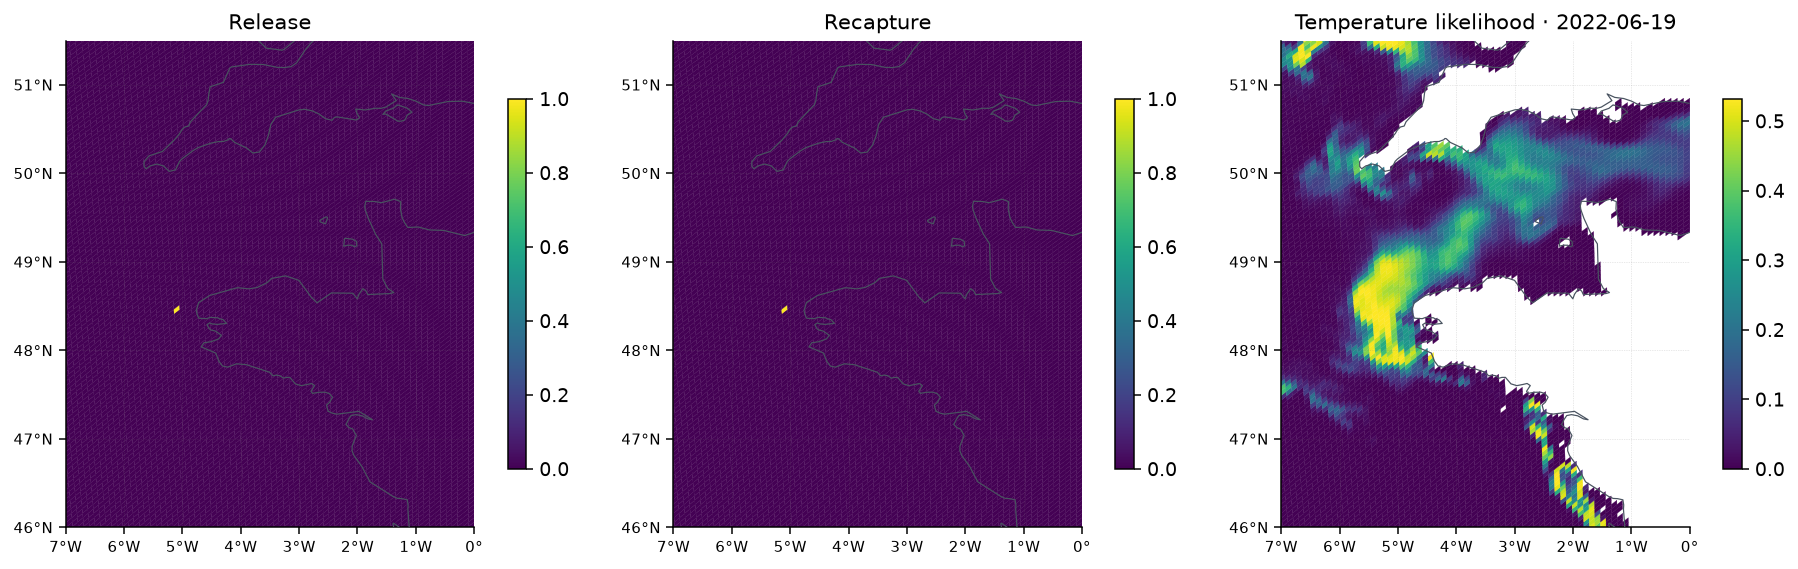

In [24]:
emission_pdf.healpix.plot(["initial", "final", "pdf"])

各時刻の水温による尤度（likelihood）の合計 `total = sum(dims, min_count=1)` を確認します。この段階では 1 になる必要はありません。

- `NaN`：その時刻にはデータがありません。
- `0`：データはありますが、タグの水温と一致する場所がひとつもありません。

どちらかが現れたら、先に進む前に原因を調べてください。

Time steps without data (NaN): 0
Time steps with zero total weight: 0


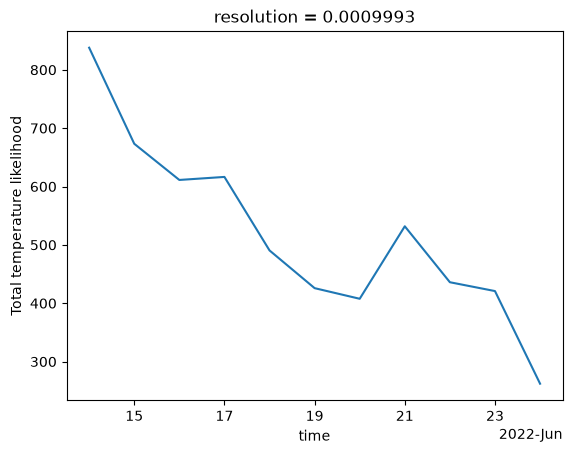

In [25]:
emission_pdf = emission_pdf.chunk(default_chunk_dims).persist()
total = (
    emission_pdf["pdf"].sum(dims, min_count=1).rename("Total temperature likelihood")
)
print("Time steps without data (NaN):", int(total.isnull().sum()))
print("Time steps with zero total weight:", int((total == 0).sum()))
total.plot()

In [26]:
# データセットを保存します
emission_pdf.to_zarr(
    f"{target_root}/emission_diff.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

In [27]:
emission_pdf.attrs["sources"] = emission_pdf.attrs.get("sources", []) + [
    "temperature"
]  # これまでに加えた手がかりの種類を記録します。
emission_pdf.to_zarr(
    f"{target_root}/total_pdf.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

## 5. 音響テレメトリーの受信記録を加える

受信記録は、その時刻に魚が受信機の想定受信範囲の中にいたことを教えてくれます。この情報を使って、水温による手がかりを補いながら、魚がいた可能性のある場所を絞り込みます。

このステップには、タグのデータに音響テレメトリーの受信記録と受信機の位置が含まれている必要があります。設定 `receiver_buffer` で想定する受信範囲を決めます。この手がかりは、セクション 6 で水温の手がかりと統合します。

くわしい説明は[音響観測による位置制約：検出と非検出](science/05_acoustic.md)を見てください。

In [28]:
from pangeo_fish.helpers import compute_acoustic_pdf

In [29]:
# 受信記録の時刻の単位を、ほかのデータと同じナノ秒にそろえます。
# pandas 3 では受信記録の時刻がマイクロ秒で読み込まれ、単位が違うと
# 受信記録を 1 件も数えられません（pangeo-fish の不具合を避けるための処理です）。
acoustic = tag["acoustic"].to_dataset()
tag["acoustic"] = acoustic.assign_coords(time=acoustic["time"].astype("datetime64[ns]"))

In [30]:
# 前のステップの観測確率を読み込み、音響テレメトリーの受信記録にもとづく観測確率を計算します
emission_diff = xr.open_dataset(
    f"{target_root}/emission_diff.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
acoustic_pdf = compute_acoustic_pdf(
    emission_ds=emission_diff,
    tag=tag,
    receiver_buffer=receiver_buffer,
    chunk_time=chunk_time,
    dims=dims,
)[0]
acoustic_pdf = acoustic_pdf.persist()
acoustic_pdf

<xarray.Dataset> Size: 912kB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    longitude   (cells) float64 65kB 0.04777 0.04782 0.04787 ... 353.3 353.1
    latitude    (cells) float64 65kB 46.01 46.06 46.11 ... 51.53 51.53 51.53
  * cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=10, indexing_scheme=nested, kind=pandas)
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    receiver_buffer:           2000 meter

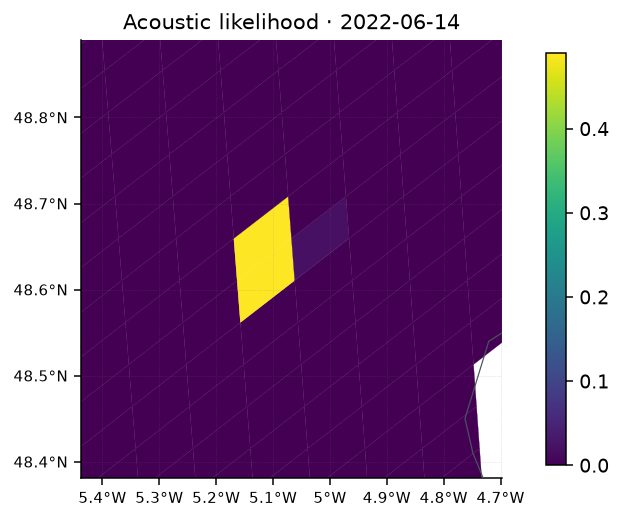

In [31]:
acoustic_pdf.healpix.plot("acoustic")

次のプロットは、受信の時刻と、セル数を数えた診断用の曲線を比べるものです。受信の時刻の前後で変化があるかを見てください。

ここでは、`acoustic != 0` を満たすセルを数えています。欠損値もこの条件を満たすため、この曲線は魚がいた可能性のある場所の正確な数ではありません。この点に注意して読み取ってください。

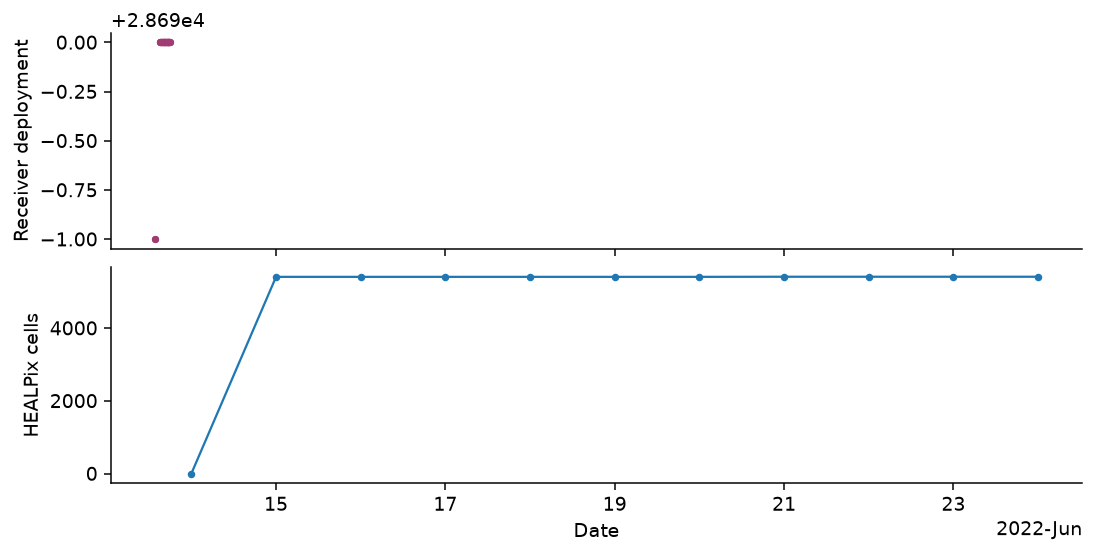

In [32]:
tag["acoustic"]["deployment_id"].hvplot.scatter(c="red", marker="x") * (
    acoustic_pdf["acoustic"] != 0
).sum(dim=dims).hvplot()

受信があった時刻には、想定した受信範囲のもとで、可能性のある場所が受信機の周りに一気に絞り込まれることがあります。受信記録は、位置を強く制約する手がかりです。曲線の高さを可能性のある場所の正確な数と考えるのではなく、受信の時刻と合わせて曲線の変化を読み取ってください。

次のセルでは、必要に応じて音響テレメトリーの結果を別に保存します。このあとの解析では、すでに計算した結果をそのまま使えます。

In [33]:
acoustic_pdf.to_zarr(
    f"{target_root}/acoustic.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

### 手がかりをまとめる

In [34]:
# いま保存されている手がかりを開きます。
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
current_total

<xarray.Dataset> Size: 1MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    cell_ids    (cells) int64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    latitude    (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude   (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B ...
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    initial     (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    pdf         (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature']

In [35]:
if "acoustic" in current_total.data_vars:
    pass
else:
    current_total = current_total.load()
    current_total.attrs["sources"] = current_total.attrs.get("sources", []) + [
        "acoustic"
    ]

    merged_pdf = current_total.merge(
        acoustic_pdf.drop_indexes(["cell_ids"]), compat="override"
    )

    merged_pdf.to_zarr(
        f"{target_root}/total_pdf.zarr",
        mode="w",
        consolidated=True,
        storage_options=storage_options,
        zarr_format=2,
    )
merged_pdf

<xarray.Dataset> Size: 2MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
    latitude    (cells) float64 65kB 46.01 46.06 46.11 ... 51.53 51.53 51.53
    longitude   (cells) float64 65kB 0.04777 0.04782 0.04787 ... 353.3 353.1
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B 0.0009993
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    initial     (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    mask        (cells) float64 65kB 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0 1.0
    pdf         (time, cells) float64 717kB nan nan nan ... 0.0108 0.001587
    acoustic    (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature', 'acoustic']

## 6. 水温と音響テレメトリーの手がかりを統合する

水温の重みと音響テレメトリーの重みを掛け合わせ、最終位置の情報があればそれも加えます。そのうえで、各時刻で合計が 1 になるように、セル全体の重みの合計で割ります。これを**正規化**と呼びます。

この結果は、観測から見て、それぞれの候補の場所がどのくらい支持されるかを表します。場所を時間方向につなぐには、さらに移動モデルが必要です。

In [36]:
from pangeo_fish.helpers import combine_pdfs
from pangeo_fish.helpers import normalize_pdf

In [37]:
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
current_total

<xarray.Dataset> Size: 2MB
Dimensions:     (time: 11, cells: 8145)
Coordinates:
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    cell_ids    (cells) int64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    latitude    (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude   (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    resolution  float64 8B ...
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
    final       (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    initial     (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    pdf         (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature', 'acoustic']

In [38]:
emission_pdf = normalize_pdf(
    ds=current_total,
    chunks=default_chunk_dims,
    dims=dims,
    exclude=("initial", "final", "mask"),
    excluded_pdf=None,  # ("acoustic",)
)[0]

emission_pdf.to_zarr(
    f"{target_root}/combined.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
combined = emission_pdf

emission_pdf["pdf"].sum(dims).hvplot(
    width=500, ylim=(0, 2), title="Total probability per time step"
)

確率の合計は、どの時刻でもほぼ **1** になるはずです。データのない時刻も、1 からずれた値（合計が 0）として現れます。そのような時刻があれば、移動モデルを推定する前に原因を調べてください。

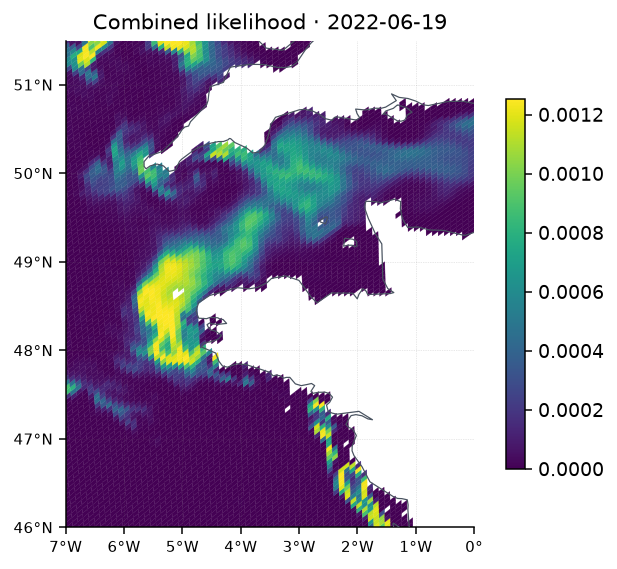

In [39]:
combined.healpix.plot("pdf")

## 7. 魚がどのくらいの範囲を移動できるかを推定する

移動モデルは、連続する時刻のあいだで、魚がいた可能性のある場所どうしをつなぎます。そのパラメータ `sigma` は、移動がどのくらい広がりうるかを決めます。値が大きいほど、より広い範囲の移動を許します。このパラメータを観測から推定します。

次のセルを実行して、移動のパラメータを推定し、保存します。探索が警告なしに終わることを確認してください。表示される `f(x)` の値は、試した `sigma` の値での当てはまりの良さを表します。探索ではいろいろな値を試すので、毎回改善しなくても問題ありません。

移動の時間間隔は、データの日付から決まります。動画の設定 `time_step` を変えても、モデルの中の魚の移動は変わりません。

<details>
<summary>補足：パラメータの探索のしくみ</summary>

探索にはブレント法（Brent's method）を使い、`1e-4` ラジアンから上限 `maximum_speed × Δt × adjustment_factor / earth_radius` までの範囲で探します。ここで Δt は観測確率の時間座標の間隔、`earth_radius` は HEALPix 格子に保存された楕円体から求めた地球の半径（長半径。`"WGS84"` の場合は約 6378 km）です。速度の設定は `sigma` の探索範囲を決めるもので、ありうる移動のひとつひとつを厳密に制限するものではありません。

推定された値が探索範囲の端に近くないかを確認してください。探索が収束しても、その解がただひとつであることや、全体での最適解であることが保証されるわけではありません。付録では、別の値と比べることができます。推定したパラメータと計算の設定は、次のステップのために JSON ファイルに保存されます。

</details>

In [40]:
from pangeo_fish.helpers import optimize_pdf

In [41]:
# 確率分布を開きます
emission = xr.open_dataset(
    f"{target_root}/combined.zarr",
    engine="zarr",
    chunks={},
    inline_array=True,
    storage_options=storage_options,
).chunk(default_chunk_dims)
emission

<xarray.Dataset> Size: 1MB
Dimensions:     (cells: 8145, time: 11)
Coordinates:
    cell_ids    (cells) int64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    latitude    (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    longitude   (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
  * time        (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
    resolution  float64 8B ...
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    initial     (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    mask        (cells) float64 65kB dask.array<chunksize=(8145,), meta=np.ndarray>
    pdf         (time, cells) float64 717kB dask.array<chunksize=(1, 8145), meta=np.ndarray>
Attributes: (12/16)
    pit_tag_id:                A19124
    acoustic_tag_id:           OPI-372
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A19124
    ...                        ...
    level:                     10
    nside:                     1024
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001
    sources:                   ['temperature', 'acoustic']

In [42]:
# パラメータの範囲を決め、最適な値を探します
params = optimize_pdf(
    ds=emission,
    adjustment_factor=adjustment_factor,
    truncate=truncate,
    maximum_speed=maximum_speed,
    tolerance=tolerance,
    dims=dims,
    # 結果はそのまま保存できます
    save_parameters=True,
    storage_options=storage_options,
    target_root=f"{target_root}",
    conv_method="FFTConv",  # FFT による高速な畳み込み。sigma に対してなめらかに変化します。"HealpixConv" は時間のかかる基準となる手法
)
params

 
 Func-count     x          f(x)          Procedure
    1     0.00365501      401.516        initial
    2     0.00585213      404.604        golden
    3     0.00229712      399.415        golden
    4     0.00145789      397.991        golden
    5    0.000939224      396.977        golden
    6    0.000618669       396.18        golden
    7    0.000420555      395.066        golden
    8    0.000298114      394.183        golden
    9    0.000222441      394.108        golden
   10    0.000244507      394.113        parabolic
   11    0.000227244      394.109        parabolic
   12    0.000215698      394.108        parabolic
   13    0.000171505      394.108        golden
   14      0.0001884      394.108        parabolic


   15    0.000178632      394.108        parabolic
   16    0.000172084      394.108        parabolic
   17    0.000168006      394.108        parabolic
   18     0.00014203      394.108        golden
   19    0.000152835      394.108        parabolic
   20    0.000146963      394.108        parabolic
   21    0.000143118      394.108        parabolic
   22     0.00014065      394.108        parabolic
   23    0.000125123      394.108        golden
   24    0.000131497      394.108        parabolic
   25    0.000128003      394.108        parabolic
   26    0.000125587      394.108        parabolic
   27    0.000124661      394.108        parabolic
   28    0.000115241      394.108        golden


   29    0.000118746      394.108        parabolic
   30    0.000116993      394.108        parabolic
   31    0.000116324      394.108        golden
   32    0.000115911      394.108        golden
   33    0.000115577      394.108        golden

Optimization terminated successfully;
The returned value satisfies the termination criteria
(using xtol =  1e-06 )


({'sigma': [0.0001155772346853307],
  'predictors': None,
  'predictor_factory': {'class': "<class 'pangeo_fish.hmm.prediction.FFTGaussian1DHealpix'>",
   'kwargs': {'grid_info': "HealpixInfo(level=10, ellipsoid='WGS84', indexing_scheme='nested')",
    'sigma': 'None',
    'truncate': '5',
    'kernel_size': 'None',
    'max_sigma': '0.009407135657324388',
    'max_kernel_size': 'None',
    'pixel_size_rad': 'None',
    'ellipsoid': 'WGS84',
    'max_patch_radius_deg': '10.0',
    'device': 'cpu',
    'dtype': 'torch.float64',
    'projection': 'conservative'}},
  'comment': 'pangeo-fish == 2026.11.2, healpix-convolution == 0.1.2, xarray == 2026.9.0, xhealpixify == 2025.3.3'},
 <xarray.Dataset> Size: 1MB
 Dimensions:     (cells: 8145, time: 11)
 Coordinates:
   * cell_ids    (cells) int64 65kB 703406 703407 703418 ... 3624964 3624968
     latitude    (cells) float64 65kB 46.01 46.06 46.11 ... 51.53 51.53 51.53
     longitude   (cells) float64 65kB 0.04777 0.04782 0.04787 ... 353.3 353.

## 8. 位置を推定し、移動経路をまとめる

観測による手がかりと、推定した移動モデルを組み合わせて、各時刻にそれぞれの候補の場所に魚がいた確率を推定します。この確率分布を、次の 3 通りの方法でまとめます。

- **`viterbi_healpix`：** ビタビ（Viterbi）アルゴリズムで求めた、もっとも確からしい位置の系列全体。
- **`mode`：** 各時刻で確率がもっとも高いセル（最頻値）。
- **`mean`：** 各時刻の平均の位置。

これらの線は推定した確率分布の要約であり、実際に観測された経路ではありません。読み取るときは、確率が地図上でどのくらい広がっているかもあわせて確認してください。移動経路の連続する点のあいだの距離を km で、それに対応する速度を km/h で計算します。

<details>
<summary>補足：ほかの移動経路の求め方と計測値</summary>

ビタビ（Viterbi）アルゴリズムは、時刻ごとに別々に要約するのではなく、もっとも確からしい位置の系列全体を求めます。

`additional_track_quantities` の設定に指定できるのは `"speed"` と `"distance"` だけです。解析のあとで、返された移動経路から MovingPandas を使って、加速度（`add_acceleration`）、方向（`add_direction`）、方向の変化（`add_angular_difference`）、時間間隔（`add_timedelta`）を計算できます。これらは別の処理ステップです。[MovingPandas の trajectory API](https://movingpandas.readthedocs.io/en/main/api/trajectory.html) を参照してください。

</details>

移動経路の求め方のくわしい説明は[HMM による位置分布と移動経路の推定](science/02_hmm.md)を見てください。

In [43]:
from pangeo_fish.helpers import compute_states

states = compute_states(
    target_root=f"{target_root}",
    storage_options=storage_options,
    chunks=default_chunk_dims,
    save=True,
)

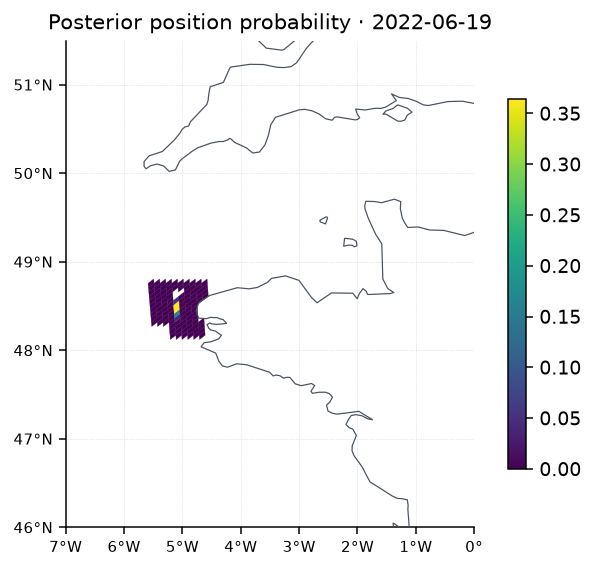

In [44]:
states.healpix.plot(["states"])

`states` の確率は、各時刻で合計がほぼ **1** になるはずです。1 からずれている場合は、その時刻に欠損値や不正な値があることを意味します。

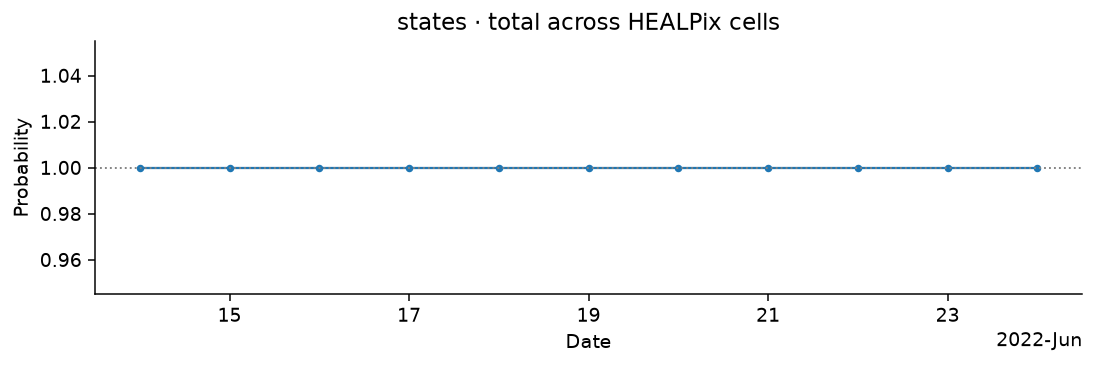

In [45]:
states["states"].sum(dims).hvplot(
    width=500, ylim=(0, 2), title="Total probability per time step"
)

## 9. 地図と移動経路を見る

ビタビ（viterbi_healpix）、最頻値（mode）、平均（mean）の移動経路を比べ、確率の地図が時間とともにどう変わるかを見てみましょう。魚の位置がはっきり絞り込まれているのはどこでしょうか？ 可能性のある海域がいくつも残っているのはどこでしょうか？

**観測確率（emission）** の地図は、観測による手がかりを示します。**状態確率（state）** の地図は、時刻間の移動も考慮しています。両者のパターンを比べて、移動モデルが推定位置にどう影響しているかを確認してください。

### 9.1 移動経路を比べる

3 つの移動経路は、どこで一致し、どこで食い違っていますか？ 確率の地図を使って、その違いを読み解いてください。

比べ方と検証の考え方は[手法を比較し、推定結果を検証する](science/08_comparison_validation.md)を見てください。

In [46]:
from pangeo_fish.helpers import decode_trajectories

trajectories = decode_trajectories(
    target_root=f"{target_root}",
    storage_options=storage_options,
    chunks=default_chunk_dims,
    track_modes=track_modes,
    additional_track_quantities=additional_track_quantities,
    save=True,
)

True
début
T=11,n=8145
début neighbors
nombre de sigmas demandés : 1
sigmas uniques utilisés   : 1
valeurs                   : [0.00011558]
transitions par sigma    : [10]
n=8145, T=11, level=10
sigma=0.0001156 rad | rings=2 | M(candidats)=25 | K(valides)=1 | taille table ~0 Mo
fin neighbors
fin


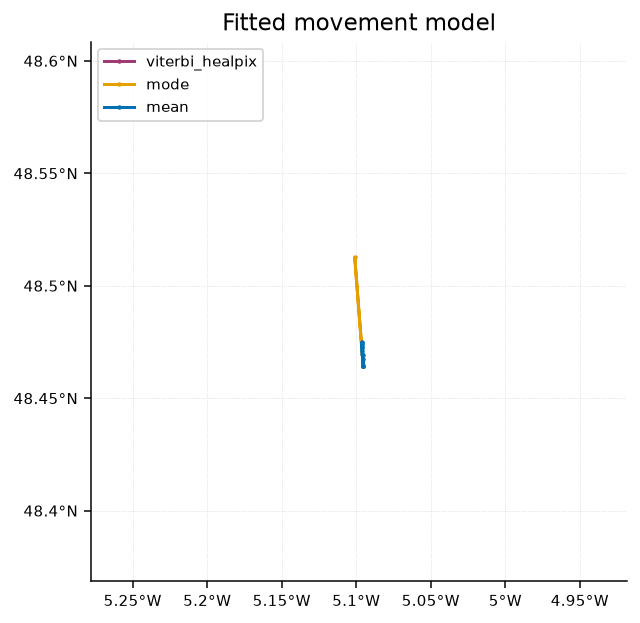

In [47]:
from pangeo_fish.helpers import plot_trajectories

plot_trajectories(
    target_root=f"{target_root}",
    track_modes=track_modes,
    storage_options=storage_options,
    save_html=True,
)

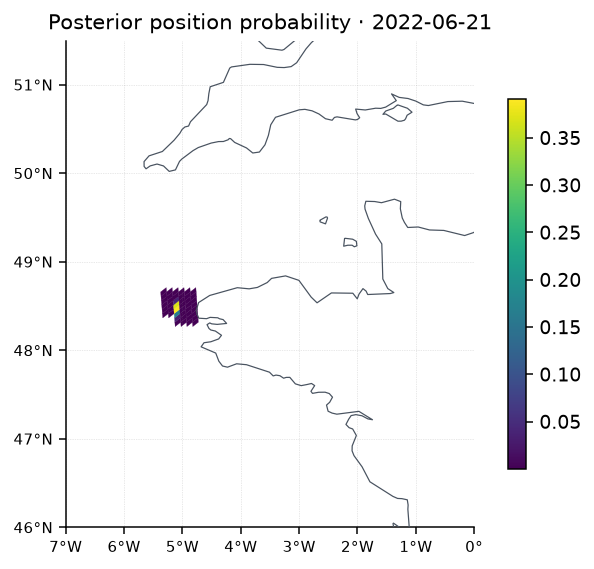

In [48]:
states.healpix.plot(["states"])

### 9.2 確率分布の時間変化を見る

In [49]:
from pangeo_fish.helpers import open_distributions, render_distributions

In [50]:
data = open_distributions(
    target_root=target_root,
    storage_options=storage_options,
    chunks=default_chunk_dims,
    chunk_time=chunk_time,
)
data

[KNeighborsResampler] dropping 76 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).


<xarray.Dataset> Size: 4MB
Dimensions:    (time: 11, latitude: 198, longitude: 252)
Coordinates:
  * time       (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
  * latitude   (latitude) float64 2kB 46.0 46.03 46.06 ... 51.44 51.47 51.5
  * longitude  (longitude) float64 2kB -7.0 -6.972 -6.944 ... -0.02789 0.0
Data variables:
    states     (time, latitude, longitude) float32 2MB dask.array<chunksize=(1, 198, 252), meta=np.ndarray>
    emission   (time, latitude, longitude) float32 2MB dask.array<chunksize=(1, 198, 252), meta=np.ndarray>

上の出力は、プロットに使えるデータの概要です。次のセルを実行すると、MP4 のアニメーションが作られ、コードのすぐ下で再生されます。

`time_step = 1` はデータのすべての時刻でフレームを作り、`3` は 3 時刻ごとにフレームを作ります。変わるのは動画のコマの間引きだけです。現在の動画作成ツールでは、この設定が 1 でも、最後の時刻は含まれません。

可能性のある場所が絞り込まれる時期や広がる時期に注目し、音響テレメトリーの受信の時刻と比べてみてください。

In [51]:
import numpy as np

lon = data["longitude"].values  # (nx,)
lat = data["latitude"].values  # (ny,)
lon_2d, lat_2d = np.meshgrid(
    lon, lat
)  # (ny, nx)、2 次元の地理座標

data_2d = data.rename({"latitude": "y", "longitude": "x"})
data_2d = data_2d.assign_coords(
    longitude=(("y", "x"), lon_2d),
    latitude=(("y", "x"), lat_2d),
)
data_2d

<xarray.Dataset> Size: 5MB
Dimensions:    (time: 11, y: 198, x: 252)
Coordinates:
  * time       (time) datetime64[ns] 88B 2022-06-14 2022-06-15 ... 2022-06-24
  * y          (y) float64 2kB 46.0 46.03 46.06 46.08 ... 51.42 51.44 51.47 51.5
  * x          (x) float64 2kB -7.0 -6.972 -6.944 ... -0.05578 -0.02789 0.0
    longitude  (y, x) float64 399kB -7.0 -6.972 -6.944 ... -0.05578 -0.02789 0.0
    latitude   (y, x) float64 399kB 46.0 46.0 46.0 46.0 ... 51.5 51.5 51.5 51.5
Data variables:
    states     (time, y, x) float32 2MB dask.array<chunksize=(1, 198, 252), meta=np.ndarray>
    emission   (time, y, x) float32 2MB dask.array<chunksize=(1, 198, 252), meta=np.ndarray>

In [52]:
video_filename = render_distributions(
    data=data_2d,
    output_path=f"{target_root}/states",
    xlim=bbox["longitude"],
    ylim=bbox["latitude"],
    time_step=time_step,
    extension="mp4",
    frames_dir="video",
    remove_frames=True,
    storage_options=storage_options,
)

  0%|          | 0/10 [00:00<?, ?it/s]

Rendering the video...:   0%|          | 0/10 [00:00<?, ?it/s]

Rendering the video...:  10%|█         | 1/10 [00:01<00:11,  1.29s/it]

Rendering the video...: 100%|██████████| 10/10 [00:01<00:00,  7.35it/s]

0it [00:00, ?it/s]

Removing .png files: : 0it [00:00, ?it/s]

Removing .png files: : 10it [00:00, 7930.24it/s]

In [53]:
from IPython.display import Video, display

display(Video(filename=video_filename, embed=True))

## 10. 次のステップ：GFTS で見る、将来の海での魚の姿

結果は、次のセルで表示される出力フォルダーに保存されています（`states.zarr` と `trajectories.parq`）。これらを Destination Earth の Global Fish Tracking Service で将来の海水温と並べて表示する方法は、「[将来の海での魚の姿：GFTS](https://pangeo-fish.github.io/pangeo-fish-fra2026/gfts.html)」に進んでご覧ください。そのあと、短い[アンケート](https://pangeo-fish.github.io/pangeo-fish-fra2026/feedback.html)へのご回答をお願いします。


In [54]:
print("Your results are in:", target_root)

Your results are in: ./test/wgs84/level10/A19124


## 研究で使うときは

このノートブックの手法を自分の研究で使った場合は、pangeo-fish の論文（Magin et al., 2026, *Journal of Open Source Software*, [doi:10.21105/joss.08332](https://doi.org/10.21105/joss.08332)）を引用してください。一緒に引用するデータやツール、pangeo-fish を使った研究の一覧は「[研究で pangeo-fish を使ったら：引用のしかた](cite.md)」のページにまとめています。

## 補足の付録：移動の仮定を比べる

ワークショップの本編はここまでです。移動の仮定がどう影響するかを調べたい方のために、次のセルでは、推定したモデルと、指定した 2 つの `sigma` の値によるモデルを比べます。確率の地図と移動経路がどう変わるかを見てください。

比較ごとに別の出力フォルダーを使います。最初の比較では、用意された設定のまま使ってください。より発展的な解析では、期間ごとに異なる移動のパラメータを使うこともできます。

In [55]:
import json
import warnings
from pathlib import Path
import fsspec
from pangeo_fish.helpers import create_parameters, hand_test_parameter
from pangeo_fish.helpers import optimize_pdf

まず、統合した観測確率の分布を別の出力フォルダーにコピーします。

In [56]:
# 確率分布を開きます
emission = xr.open_dataset(
    f"{target_root}/combined.zarr",
    engine="zarr",
    chunks={},
    inline_array=True,
    storage_options=storage_options,
).chunk(default_chunk_dims)
# 新しいフォルダーを作ります
emission.to_zarr(
    f"{target_root}/hand_sigma0.1/combined.zarr",  # "hand_sigma0.1" は別の名前に変えてもかまいません
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

指定した移動のパラメータを、同じフォルダーに保存します。

In [57]:
params = create_parameters(
    sigma=[0.0003],
    sigma_indices=None,
    n_steps=emission.sizes["time"],
    single_behav=True,
    class_name="FFTGaussian1DHealpix",  # 移動モデルの畳み込みクラス。
    target_root=f"{target_root}/hand_sigma0.1",  # 上で使ったフォルダーと同じにします。
    save_parameters=True,
)

別の方法として、`hand_test_parameter()` を使うと、統合した観測確率の分布と指定したパラメータを比較用のフォルダーに保存できます。既存のデータセットを `emission` として渡すか、`None` のままにしてセクション 6 の `combined.zarr` を読み込みます。

In [58]:
params = hand_test_parameter(
    emission=None,
    sigma_tested=[0.03],
    sigma_indices=None,
    Conv_method="FFTGaussian1DHealpix",
    target_root=target_root,
    saving_root="/hand_sigma10",
    default_chunk_dims=default_chunk_dims,
    storage_options=storage_options,
)

In [59]:
from pangeo_fish.helpers import compute_states

states_list = [
    compute_states(
        target_root=f"{target_root}/{subfolder}",
        storage_options=storage_options,
        chunks=default_chunk_dims,
        save=True,
    )
    for subfolder in [
        "",
        "hand_sigma0.1",
        "hand_sigma10",
    ]
]

同期した地図で状態確率の分布を比べ、その下で移動経路を比べます。

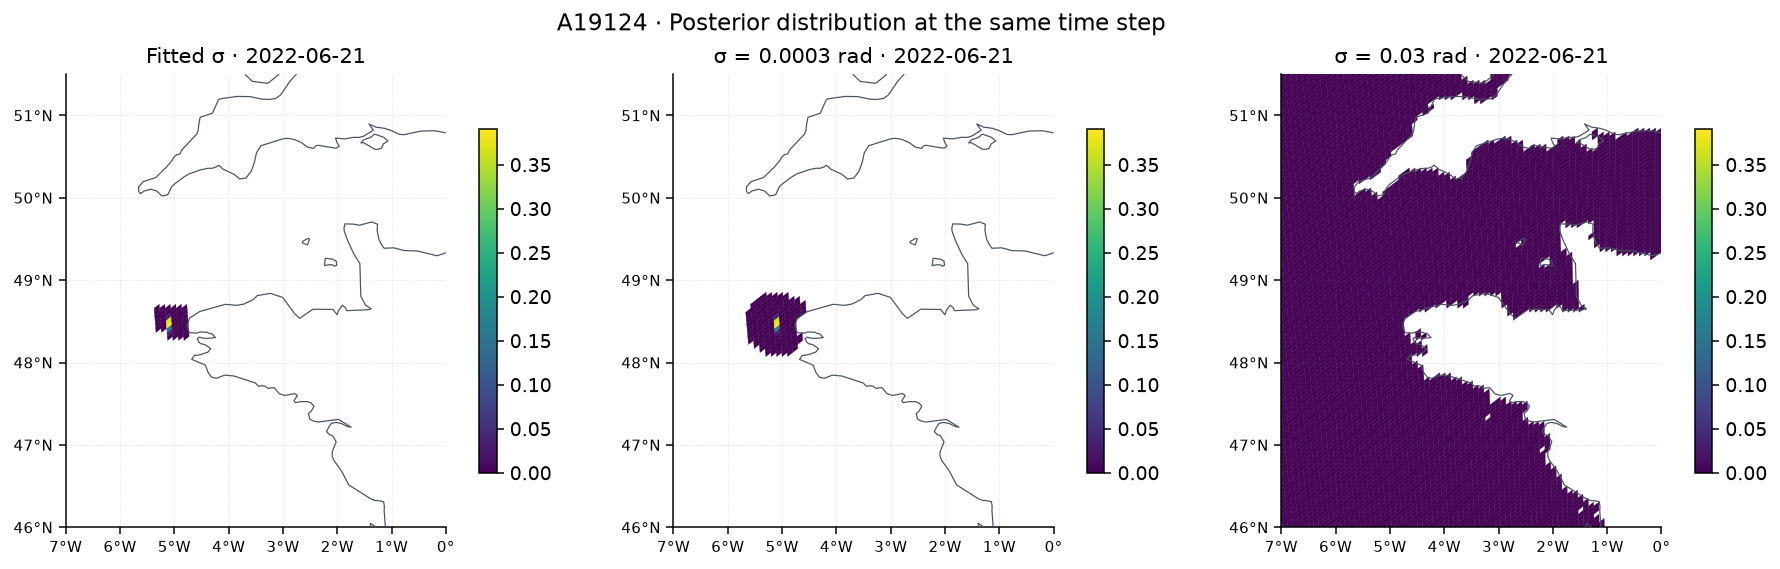

In [60]:
from pangeo_fish.helpers import multi_map_with_synced_sliders, multiplot_healpix

liste = multiplot_healpix(
    [
        (states_list[0], ["states"]),
        (states_list[1], ["states"]),
        (states_list[2], ["states"]),
    ],
)
liste

multi_map_with_synced_sliders(liste)

True
début
fin


True
début
fin


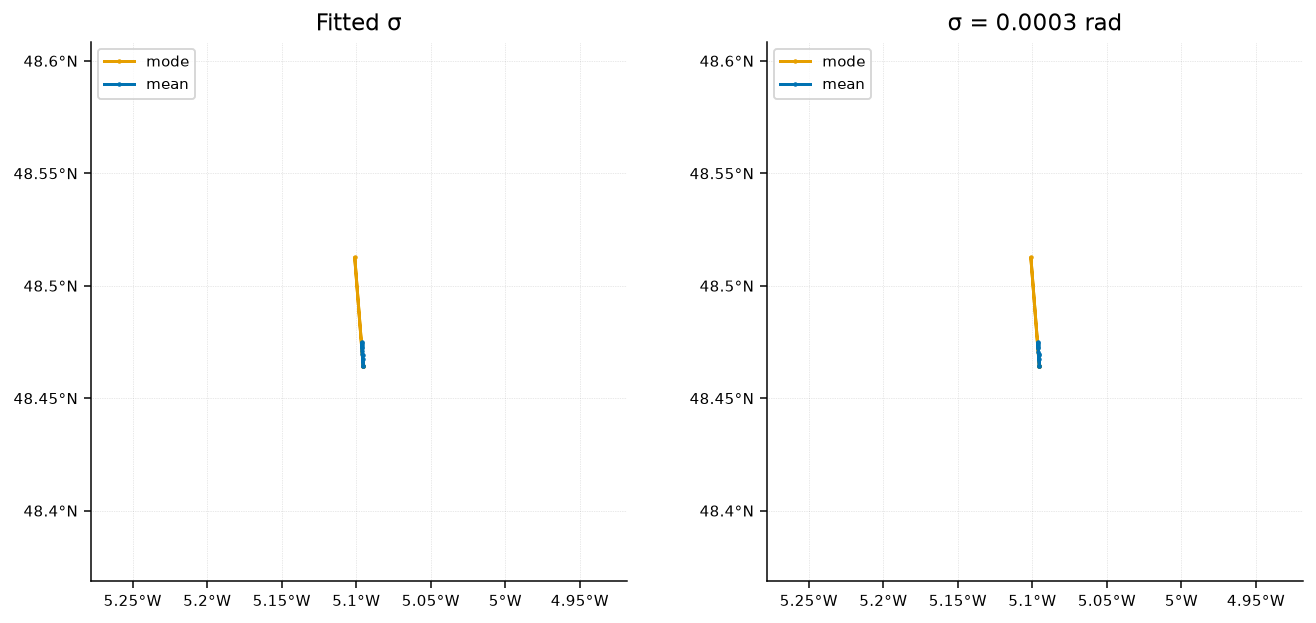

In [61]:
from pangeo_fish.helpers import decode_trajectories, plot_trajectories

traj_list = [
    decode_trajectories(
        target_root=f"{target_root}/{subfolder}",
        storage_options=storage_options,
        track_modes=comparison_track_modes,
        chunks=default_chunk_dims,
        save=True,
    )
    for subfolder in [
        "",
        "hand_sigma0.1",
    ]
]

traj_plots = [
    plot_trajectories(
        target_root=f"{target_root}/{subfolder}",
        track_modes=comparison_track_modes,
        storage_options=storage_options,
        save_html=True,
    ).options(title=f"Model's Folder: {subfolder}")
    for subfolder in [
        "",
        "hand_sigma0.1",
    ]
]
(traj_plots[0] + traj_plots[1]).cols(3)

## 付録：バグ報告用の情報（Information for bug reports）

うまく動かないときは、どのソフトウェアを使っていたかを正確に知る必要があります。次のセルを実行し（前のセルでエラーが出ていても、いつでも実行できます）、**出力をすべて**コピーして、エラーメッセージと一緒に [issue](https://github.com/pangeo-fish/pangeo-fish-fra2026/issues) やメールに貼り付けてください。

出力からは、次の 3 つのことがわかります。

- **どの計算環境か：** Jupyter サーバーの起動に使った Docker イメージ（レジストリ、名前、タグ。例：`ghcr.io/pangeo-fish/pangeo-fish-notebook:2026.11.2`）。タグの末尾は、イメージの作成に使った Pangeo-Fish のコミットです。
- **どの Pangeo-Fish のコードか：** そのイメージにインストールされている Pangeo-Fish のソースの Git リポジトリとコミット。
- **どのノートブックか：** このワークショップのリポジトリのコミットと、ノートブックを変更したかどうか。

In [62]:
# バグ報告用のソフトウェア情報：出力をすべてコピーして報告に貼り付けてください。
import os
import platform
import shutil
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version


def run(*cmd):
    try:
        result = subprocess.run(cmd, capture_output=True, text=True, check=True)
        return result.stdout.strip()
    except Exception as err:
        return f"unavailable ({type(err).__name__})"


def pkg_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


git = shutil.which("git", path=os.path.join(sys.prefix, "bin")) or "git"
fish_src = os.environ.get("PANGEO_FISH_SRC", "/srv/pangeo-fish")

print(
    "Docker image       :",
    os.environ.get("JUPYTER_IMAGE", "unknown (not set by the hub)"),
)
print(
    "JupyterHub         :",
    os.environ.get(
        "JUPYTERHUB_SERVICE_URL", os.environ.get("JUPYTERHUB_API_URL", "unknown")
    ),
)
print("Pangeo-Fish version:", pkg_version("pangeo-fish"))
print("Pangeo-Fish source :", run(git, "-C", fish_src, "remote", "get-url", "origin"))
print(
    "Pangeo-Fish commit :",
    run(git, "-C", fish_src, "log", "-1", "--format=%H (%cs) %s"),
)
print("Notebook repository:", run(git, "remote", "get-url", "origin"))
print("Notebook commit    :", run(git, "log", "-1", "--format=%H (%cs) %s"))
print("Notebook changes   :", run(git, "status", "--short", ".") or "none")
print("Python             :", sys.version.split()[0], "on", platform.platform())
for name in ["xarray", "dask", "numpy", "xdggs", "healpix-geo", "copernicusmarine"]:
    print(f"{name:19}:", pkg_version(name))